# 02 — Birliktelik kuralları

Apriori, FP-Growth ve ECLAT aynı eğitim verisi ve eşiklerle karşılaştırılır. Eşit parametrelerde aynı sık öğe kümeleri beklenir; karşılaştırma çalışma süreleri üzerinden yapılır. Önce `01_veri_ve_eda.ipynb` çalıştırılmalıdır.

In [1]:
import os
import json
import hashlib
import math
import statistics
import time
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from openpyxl import load_workbook
from mlxtend.frequent_patterns import apriori, fpgrowth

SEED = 7017
ROOT = Path.cwd()
if not (ROOT/'requirements.txt').exists():
    ROOT = ROOT.parent
WORK = Path(os.environ.get('RETAIL_NOTEBOOK_WORK', ROOT/'work'/'notebooks'))
WORK.mkdir(parents=True, exist_ok=True)


In [2]:
def save(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def chronological_split(baskets):
    first = baskets[int(len(baskets) * 0.6)]['date'][:10]
    second = baskets[int(len(baskets) * 0.8)]['date'][:10]
    train = [b for b in baskets if b['date'][:10] < first]
    valid = [b for b in baskets if first <= b['date'][:10] < second]
    test = [b for b in baskets if b['date'][:10] >= second]
    assert max((b['date'] for b in train)) < min((b['date'] for b in valid))
    assert max((b['date'] for b in valid)) < min((b['date'] for b in test))
    assert len(train) + len(valid) + len(test) == len(baskets)
    return (train, valid, test)


In [3]:
data = json.loads((WORK/'clean.json').read_text(encoding='utf-8'))
assert data['cache_policy']['seed'] == SEED, '01 notebook: SEED uyusmuyor'
assert data['sampling']['sampled_invoices'] == 50000
assert data['sha256'] == 'bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980'
train, valid, test = chronological_split(data['baskets'])
out = WORK


## ECLAT ve kural ölçüleri

ECLAT dikey işlem kümelerinin kesişimini kullanır. Destek ortak sepet oranı, güven koşullu oran, lift ise güvenin sonuç ürününün desteğine oranıdır. Güven 1 olduğunda conviction sonsuz kabul edilir.

In [4]:
def eclat(transactions, support, max_len=3):
    minimum = math.ceil(support * len(transactions) - 1e-10)
    vertical = defaultdict(set)
    for tid, transaction in enumerate(transactions):
        for item in transaction:
            vertical[item].add(tid)
    items = [(item, tids) for item, tids in sorted(vertical.items()) if len(tids) >= minimum]
    found = {}

    def visit(prefix, candidates):
        for index, (item, tids) in enumerate(candidates):
            new = prefix + (item,)
            found[frozenset(new)] = len(tids)
            if len(new) < max_len:
                following = []
                for other, other_tids in candidates[index + 1:]:
                    overlap = tids & other_tids
                    if len(overlap) >= minimum:
                        following.append((other, overlap))
                visit(new, following)
    visit((), items)
    return found


In [5]:
def rules_from_counts(counts, n):
    result = []
    for items, joint in counts.items():
        if len(items) < 2:
            continue
        ordered = sorted(items)
        for length in range(1, len(items)):
            for left in combinations(ordered, length):
                a = frozenset(left)
                b = items - a
                confidence = joint / counts[a]
                consequent_support = counts[b] / n
                result.append(dict(antecedent=sorted(a), consequent=sorted(b), support=joint / n, confidence=confidence, lift=confidence / consequent_support, conviction=None if confidence == 1 else (1 - consequent_support) / (1 - confidence), conviction_infinite=confidence == 1, joint_count=joint))
    return result


In [6]:
def evaluate_rules(rules, transactions):
    index = defaultdict(set)
    for tid, row in enumerate(transactions):
        for item in row:
            index[item].add(tid)

    def tids(items):
        return set.intersection(*(index[item] for item in items))
    results = []
    for rule in rules:
        a, b = (tids(rule['antecedent']), tids(rule['consequent']))
        both = len(a & b)
        confidence = both / len(a) if a else None
        lift = confidence / (len(b) / len(transactions)) if a and b else None
        results.append(dict(antecedent=rule['antecedent'], consequent=rule['consequent'], antecedent_count=len(a), joint_count=both, support=both / len(transactions), confidence=confidence, lift=lift))
    return results


## Ortak girdi

Ürün sözlüğü yalnız eğitim dönemindeki %2 destekle belirlenir. Filtrelemeden sonra boş kalan sepetler paydada tutulur.

In [7]:
transactions = [set(b['products']) for b in train]

valid_tx = [set(b['products']) for b in valid]

test_tx = [set(b['products']) for b in test]

freq = Counter((item for row in transactions for item in row))

vocabulary = sorted((item for item, count in freq.items() if count / len(train) >= 0.02))

frame = pd.DataFrame(np.array([[item in row for item in vocabulary] for row in transactions], dtype=bool), columns=vocabulary)

filtered = [row & set(vocabulary) for row in transactions]


## Üç yöntem ve süre ölçümü

%2, %3 ve %5 destek; en fazla 3 ürün. Üç tekrarda yöntem sırası SEED ile karıştırılır. Girdi hazırlama süreye dahil değildir; ortak sonuç biçimine dönüşüm dahildir. Her tekrarda öğe kümeleri ve tam destek sayıları karşılaştırılır.

In [8]:
timings = []

all_counts = {}

rng = np.random.default_rng(SEED)

for support in [0.02, 0.03, 0.05]:
    reference = None
    durations = defaultdict(list)
    for repetition in range(3):
        for name in rng.permutation(['apriori', 'fpgrowth', 'eclat']):
            start = time.perf_counter()
            if name == 'eclat':
                counts = eclat(filtered, support, 3)
            else:
                function = apriori if name == 'apriori' else fpgrowth
                options = dict(min_support=support, use_colnames=True, max_len=3)
                if name == 'apriori':
                    options['low_memory'] = True
                found = function(frame, **options)
                counts = {frozenset(row.itemsets): round(row.support * len(train)) for row in found.itertuples()}
            duration = time.perf_counter() - start
            durations[name].append(duration)
            if reference is None:
                reference = counts
            assert counts == reference, f'Algorithm mismatch: {name}, support {support}'
            print('Mining', support, repetition, name, len(counts), round(duration, 3), flush=True)
    all_counts[support] = reference
    for name, values in durations.items():
        timings.append(dict(algorithm=name, min_support=support, max_len=3, frequent_itemsets=len(reference), seconds=values, mean_seconds=statistics.mean(values), sample_std_seconds=statistics.stdev(values)))


Mining 0.02 0 eclat 331 0.542


Mining 0.02 0 apriori 331 0.094


Mining 0.02 0 fpgrowth 331 1.029


Mining 0.02 1 apriori 331 0.084


Mining 0.02 1 eclat 331 0.536


Mining 0.02 1 fpgrowth 331 1.123


... (23 outputs left out)

Mining 0.05 2 apriori 29 0.013


Mining

 0.05 2 fpgrowth 29 0.077


Mining 0.05 2 eclat 29 0.045


,algorithm,min_support,frequent_itemsets,mean_seconds,sample_std_seconds
0,eclat,0.02,331,0.557253,0.032262
1,apriori,0.02,331,0.088457,0.005192
2,fpgrowth,0.02,331,1.031791,0.089366
3,apriori,0.03,123,0.036115,0.001895
4,fpgrowth,0.03,123,0.490629,0.040273
5,eclat,0.03,123,0.161032,0.002758
6,fpgrowth,0.05,29,0.076697,0.000659
7,apriori,0.05,29,0.013222,0.000187
8,eclat,0.05,29,0.046120,0.001555


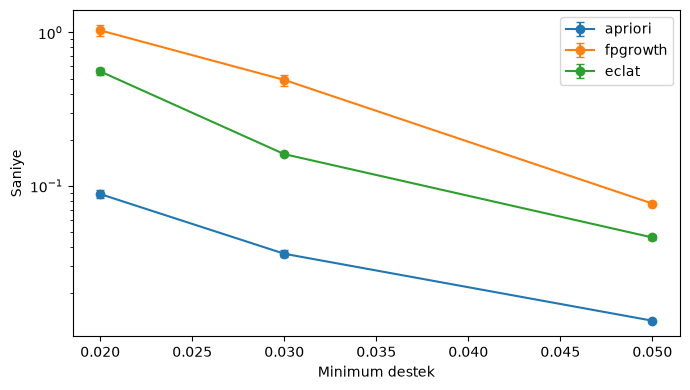

In [9]:
display(pd.DataFrame(timings)[['algorithm','min_support','frequent_itemsets','mean_seconds','sample_std_seconds']])
fig, ax = plt.subplots(figsize=(7,4))
for name in ['apriori','fpgrowth','eclat']:
    rows = sorted((r for r in timings if r['algorithm']==name), key=lambda r:r['min_support'])
    ax.errorbar([r['min_support'] for r in rows], [r['mean_seconds'] for r in rows], yerr=[r['sample_std_seconds'] for r in rows], marker='o', capsize=3, label=name)
ax.set(xlabel='Minimum destek', ylabel='Saniye', yscale='log')
ax.legend()
fig.tight_layout()
(WORK/'figures').mkdir(exist_ok=True)
fig.savefig(WORK/'figures'/'06_yontem_sureleri.jpeg', dpi=150)
plt.show()


## Eşik taraması ve dönem kontrolü

27 eşik bileşimi incelenir. Başlangıç politikası destek ≥ %2, güven ≥ %40 ve lift > 1 olarak sabittir. Test sonuçlarıyla eşik seçilmez. Sonraki dönem kontrolü daha önce incelenmiş keşifsel bir kontroldür.

In [10]:
sweep = []

for support, counts in all_counts.items():
    rules = rules_from_counts(counts, len(train))
    for confidence in [0.2, 0.4, 0.6]:
        for lift in [1, 2, 3]:
            selected = [r for r in rules if r['confidence'] >= confidence and r['lift'] > lift]
            sweep.append(dict(min_support=support, min_confidence=confidence, min_lift_exclusive=lift, rules=len(selected)))

selected = [r for r in rules_from_counts(all_counts[0.02], len(train)) if r['confidence'] >= 0.4 and r['lift'] > 1]

selected.sort(key=lambda r: (-r['lift'], -r['support'], r['antecedent'], r['consequent']))

save(out / 'mining.json', dict(seed=SEED, training_baskets=len(train), vocabulary_size=len(vocabulary), max_len=3, algorithms_agree=True, benchmark_note='3 warm-process repetitions; input preparation excluded; Python result conversion included; not a memory benchmark', timings=timings, threshold_sweep=sweep, initial_policy='support >= .02, confidence >= .4, lift > 1; exploratory, not validation-optimized', rules=selected, validation=evaluate_rules(selected, valid_tx), test=evaluate_rules(selected, test_tx), product_descriptions={item: data['descriptions'].get(item) for item in vocabulary}))


In [11]:
mining = json.loads((WORK/'mining.json').read_text(encoding='utf-8'))
display(pd.DataFrame(sweep))
display(pd.DataFrame(selected).head(10))
display(pd.DataFrame(mining['test']).head(10))
print('Seçilen kural:', len(selected))


,min_support,min_confidence,min_lift_exclusive,rules
0,0.02,0.2,1,102
1,0.02,0.2,2,98
2,0.02,0.2,3,88
3,0.02,0.4,1,61
4,0.02,0.4,2,61
5,0.02,0.4,3,57
6,0.02,0.6,1,11
7,0.02,0.6,2,11
8,0.02,0.6,3,11
9,0.03,0.2,1,14


,antecedent,consequent,support,confidence,lift,conviction,conviction_infinite,joint_count
0,[84997C],[84997D],0.020529,0.675112,21.652640,2.982013,False,453
1,[84997D],[84997C],0.020529,0.658430,21.652640,2.838633,False,453
2,[22356],[20724],0.027599,0.652034,13.079807,2.730584,False,609
3,[20724],[22356],0.027599,0.553636,13.079807,2.145498,False,609
4,[21790],[21791],0.020303,0.437073,12.492819,1.714280,False,448
5,[21791],[21790],0.020303,0.580311,12.492819,2.272035,False,448
6,[20723],[20724],0.020439,0.621212,12.461515,2.508395,False,451
7,[20724],[20723],0.020439,0.410000,12.461515,1.639150,False,451
8,[20719],[22355],0.020212,0.522248,11.880340,2.001125,False,446
9,[22355],[20719],0.020212,0.459794,11.880340,1.779502,False,446


,antecedent,consequent,antecedent_count,joint_count,support,confidence,lift
0,[84997C],[84997D],107,83,0.011197,0.775701,35.062628
1,[84997D],[84997C],164,83,0.011197,0.506098,35.062628
2,[22356],[20724],269,203,0.027384,0.754647,14.126760
3,[20724],[22356],396,203,0.027384,0.512626,14.126760
4,[21790],[21791],444,174,0.023472,0.391892,10.122281
5,[21791],[21790],287,174,0.023472,0.606272,10.122281
6,[20723],[20724],230,173,0.023337,0.752174,14.080468
7,[20724],[20723],396,173,0.023337,0.436869,14.080468
8,[20719],[22355],282,164,0.022123,0.581560,14.515510
9,[22355],[20719],297,164,0.022123,0.552189,14.515510


Seçilen kural: 61


Üç yöntem aynı kümeleri ürettiği için farklı doğruluk değerleri atamayız. Süreler bu uygulamalara ve çalıştırılan bilgisayara bağlıdır. Sonraki notebook CART ile ayrı bir ürün varlığı tahminini ele alır.